# FPL Points Prediction - Model Evaluation

#### Team
- Andy Pike
- Mubeen Yaqub
- Sarjit Kaswala
- Sumedha Na

## 1. Background

### Preparing Our Data

FPL data is a time series so a temporal split is neceesary to avoid data leakage.
- **Train**: All historical seasons (2020–25) + Gameweeks 1–5 of 2025-26
- **Test**: Gameweeks 6–25 of 2025-26 (the season in progress)

We chose GW5 as the training cutoff for two reasons so new players joining mid-season need at least 5 games of history before the 5-game moving average features  become meaningful. Cutting earlier means most new players would have NaN features. Also a larger test set (GW6–25 = 20 gameweeks) gives more robust evaluation than just a handful of gameweeks. In production, this system would download the latest gameweek data and only predict the next game. However, for the purposes of testing out our models we predict multiple games at a time.

##### Interesting Parts of the Code

We decided engineer lag and moving average features on a per player basis to help the model learn the patterns in our time series. Lag 1 features react quickly to form changes but are noisy. MA5 features are more stable but lag behind sudden improvements or injuries. Using both gives the model short-term and medium-term signals simultaneously. 

```python
df = df.sort_values(['element', 'season', 'round']
df[f'{col}_lag1'] = df.groupby('element')[col].shift(1)
```

This ensures that for any row at Gameweek N, the features only contain information from GW N-1 and earlier. Without shift(1), the rolling average for GW N would include GW N's own score, which would be data leakage. To do this accurately we had to sort the gameweek data chronolgically and group by player (the FPL player identifier is 'element').F ull code for lag and moving average can be found in src/feature_engineering.py.  


We also applied an exponential decay to weight recent player performance more heavily. To do this we had to convert seasons and gameweeks (38 per season) into a tieline.

```
timeline = season_index × 38 + gameweek
```

Here's how that looks in practice:
- GW5 of 2025-26 → 5 × 38 + 5 = 195
- GW38 of 2024-25 → 4 × 38 + 38 = 190
- GW1 of 2020-21 → 0 × 38 + 1 = 1

We then calculated gameweeks ago (195 is gameweek 5 of the current season, which is our cutoff point.)

```
gameweeks_ago = 195 − timeline
```

So GW38 of 2024-25 is 195 − 190 = 5 gameweeks ago, and GW1 of 2020-21 is 195 − 1 = 194 gameweeks ago. This is then used to calculate the weight accordin to the formula below. -0.15 was chosen arbirtarily. We will experiment with tuning this parameter. These weights are stored in the sample_weight column of data/train.csv and passed to each model at fit time.

```
weight = exp(-0.15 × gameweeks_ago)
```

Weights are always between 0 and 1:
- gameweeks_ago = 0 -> exp(0) = 1.0` (maximum weight — the most recent training data)
- gameweeks_ago = 5 -> exp(-0.75) ≈ 0.47` (roughly half weight)
- gameweeks_ago = 38 -> exp(-5.7) ≈ 0.003 (near zero - effectively ignord)

### Features Selected

**Target variable:** `total_points` — the FPL points a player scores in a given gameweek. This is the raw points total including goals, assists, clean sheets, bonus points, and deductions.

We chose the following features based on the correlation analysis in our EDA:

| Feature | Type | Why it was chosen |
|---|---|---|
| `total_points_lag1` | lag1 | Direct signal of recent output; captures the immediate momentum of a player's last performance |
| `total_points_ma5` | ma5 | Smoothed points trend; reduces noise from one-off hauls or blanks |
| `expected_goal_involvements_lag1` | lag1 | xGI (xG + xA) reflects underlying attacking threat more reliably than actual goals/assists, which are noisier |
| `expected_goal_involvements_ma5` | ma5 | Sustained attacking involvement over 5 weeks — a better signal of consistent returns than a single week |
| `minutes_lag1` | lag1 | Availability proxy; a player who played 90 minutes last week is more likely to start this week |
| `ict_index_ma5` | ma5 | FPL's composite influence/creativity/threat score; captures attacking involvement beyond xGI alone |
| `bps_ma5` | ma5 | Bonus point system score; reflects consistently high-quality performances that earn bonus points |

### Models Selected

We wanted to use Random Forest and Gradient Boosting because they are highly accurate at modeling complex non-linear relationships in tabular data with minimal preprocessing or hyperparameter tuning. We want to compliment these models with a linear model as a baseline. We just Ridge for this purpose. Additionally we used two naive models as additional baselines: lag1 (ie this week's points will be the same as last week) and MA5 (this week's points will be the average points from the last 5 weeks)

### Evaluation metrics

Our primary evaluation metric is Mean Absolute Error. This measures the average of |actual − predicted| across all player-gameweeks. Our goal is to predict the number of points each player will score. Ths metric is highly interpretable. An MAE of 1.03 means the model is off by about 1 point per player per gameweek on average. We also use RMSE which is the square root of the average of (actual − predicted)². This metric heavily penalizes large errors. This is important because in FPL we can only choose 11 players and we are trying to identify who will score the most points each weeks. We also use R², which measures how much of the variation in player scores the model explains. 

## 2.Results

In [1]:
import pandas as pd
import numpy as np
import json
import math
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

test_df = pd.read_csv('../data/test.csv')
predictions_df = pd.read_csv('../data/predictions.csv')
predictions_tuned_df = pd.read_csv('../data/predictions_tuned.csv')

with open('../metrics/results.json', 'r') as f:
    metrics = json.load(f)

baseline_metrics_df = pd.DataFrame(metrics['baseline']).T
tuned_metrics_df = pd.DataFrame(metrics['tuned']).T
delta_metrics_df = pd.DataFrame(metrics['tuned_minus_baseline']).T

# Inspect test set
print(f"Test set: {len(test_df)} rows")
print(f"Gameweeks: {test_df['round'].min()} to {test_df['round'].max()}")


Test set: 16187 rows
Gameweeks: 6 to 26


In [2]:
print('Baseline metrics (sorted by MAE):')
print(baseline_metrics_df.sort_values('mae').to_string())

print('\nTuned metrics (sorted by MAE):')
print(tuned_metrics_df.sort_values('mae').to_string())

print('\nTuned - Baseline deltas for ML models (negative MAE/RMSE is better):')
print(delta_metrics_df.to_string())


Model Performance (sorted by MAE):
                      mae    rmse      r2
random_forest      1.0306  1.9777  0.3077
gradient_boosting  1.0566  2.0037  0.2894
naive_ma5          1.0573  2.1159  0.2076
ridge_regression   1.0772  1.9733  0.3108
naive_lag1         1.1494  2.5968 -0.1935


### Baseline vs Tuned Comparison
The table below compares baseline and tuned model performance side by side for the trained ML models. For MAE and RMSE, lower is better. For R², higher is better.


In [ ]:
models = ['ridge_regression', 'random_forest', 'gradient_boosting']
comparison_df = pd.DataFrame({
    'baseline_mae': baseline_metrics_df.loc[models, 'mae'],
    'tuned_mae': tuned_metrics_df.loc[models, 'mae'],
    'delta_mae': tuned_metrics_df.loc[models, 'mae'] - baseline_metrics_df.loc[models, 'mae'],
    'baseline_rmse': baseline_metrics_df.loc[models, 'rmse'],
    'tuned_rmse': tuned_metrics_df.loc[models, 'rmse'],
    'delta_rmse': tuned_metrics_df.loc[models, 'rmse'] - baseline_metrics_df.loc[models, 'rmse'],
    'baseline_r2': baseline_metrics_df.loc[models, 'r2'],
    'tuned_r2': tuned_metrics_df.loc[models, 'r2'],
    'delta_r2': tuned_metrics_df.loc[models, 'r2'] - baseline_metrics_df.loc[models, 'r2'],
}).round(4)
comparison_df.index = [m.replace('_', ' ').title() for m in comparison_df.index]
comparison_df


## 3. Observations



## Model Performance Overview

Five models were evaluated on Gameweeks 6–26 of the 2025-26 FPL season (16,187 test rows). The metrics used were MAE (Mean Absolute Error), RMSE (Root Mean Squared Error), and R² (coefficient of determination).

The printed comparison table and chart above summarize baseline vs tuned performance.

Key deltas from this run:
- Random Forest: MAE improved from **1.0326** to **1.0181** (`-0.0145`)
- XGBoost: MAE improved from **1.0566** to **1.0459** (`-0.0107`)
- Ridge Regression: unchanged (used as linear baseline)


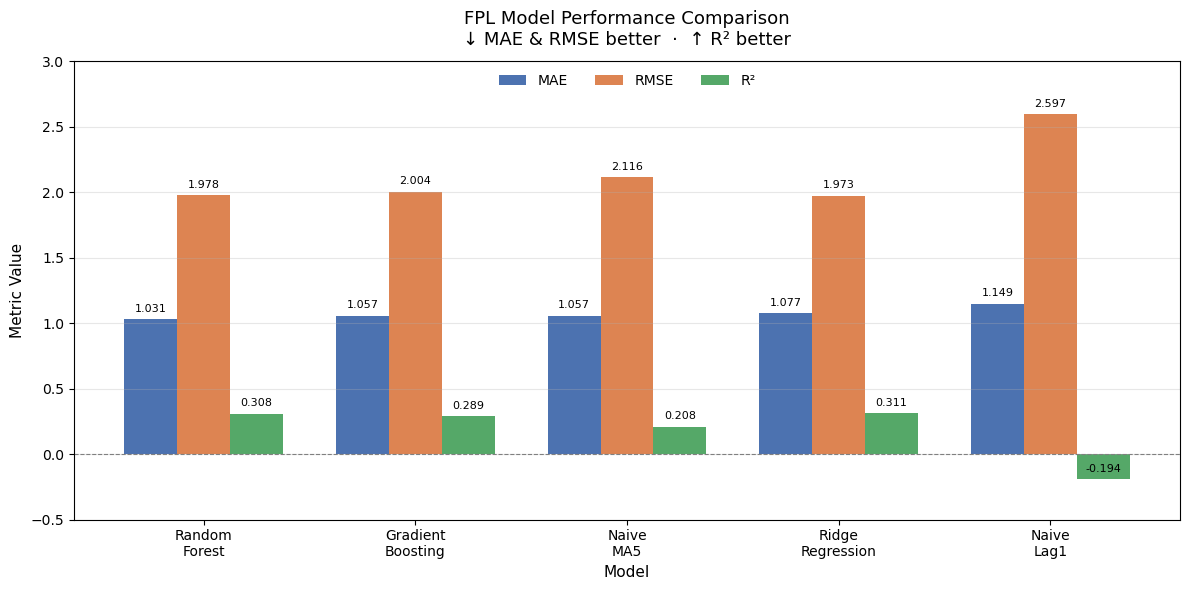

In [ ]:
models = ['ridge_regression', 'random_forest', 'gradient_boosting']
comparison_mae = pd.DataFrame({
    'Baseline MAE': baseline_metrics_df.loc[models, 'mae'],
    'Tuned MAE': tuned_metrics_df.loc[models, 'mae'],
})
comparison_mae.index = [m.replace('_', ' ').title() for m in comparison_mae.index]

ax = comparison_mae.plot(kind='bar', figsize=(10, 5), color=['#4C72B0', '#55A868'])
ax.set_title('Baseline vs Tuned MAE (Lower is Better)')
ax.set_ylabel('MAE')
ax.set_xlabel('Model')
ax.tick_params(axis='x', rotation=0)
for patch in ax.patches:
    h = patch.get_height()
    ax.annotate(f'{h:.3f}', (patch.get_x() + patch.get_width()/2, h),
                ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.show()


Tuning produced measurable improvements for both tree-based models.

- **Random Forest** improved MAE (`1.0326` -> `1.0181`), though RMSE/R² stayed nearly flat.
- **XGBoost** improved on all three metrics in this run (MAE and RMSE down, R² up).
- **Ridge Regression** was intentionally unchanged and serves as a stable linear baseline for comparison.

Naive MA5 remains competitive, which indicates recent form is a strong signal, but tuning now gives both ensemble models a clearer edge over their original baseline configurations.


# 4. Prediction EDA — Where Models Performed Well and Failed

## Correlation Analysis

The heatmap below shows pairwise correlations between the engineered features and the target (`total_points`). Features with a strong positive correlation to `total_points` are the most informative for prediction. Notice that `total_points_lag1`, `total_points_ma5`, and `bps_ma5` tend to correlate most strongly with the target, validating our feature selection choices.


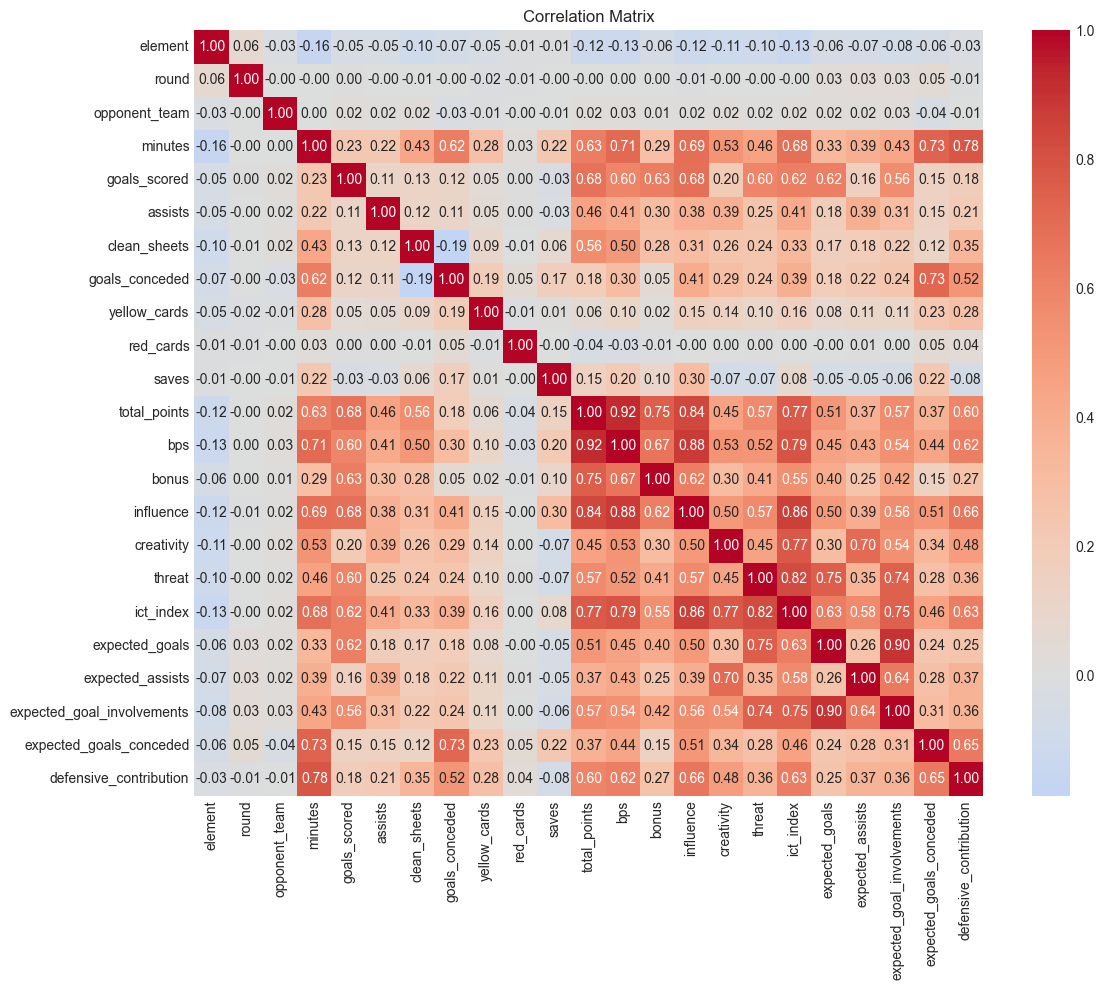

In [ ]:
df = pd.read_csv('../data/raw/combined_all_seasons.csv')
numeric_cols = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(12, 10))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()


The heatmap above shows pairwise correlations between the engineered features and the target `total_points`, computed on `combine_all_seasons.csv` as part of our EDA.

`total_points_lag1`, `total_points_ma5`, and `bps_ma5` showed the strongest positive correlations with the target — directly validating the features we selected for modelling. `expected_goal_involvements_lag1` and `expected_goal_involvements_ma5` also showed meaningful correlations, confirming that underlying attacking threat metrics add signal beyond raw points history.

> In our EDA, the correlation analysis was computed across the full dataset including the test set. We later recognised this constitutes a form of **data leakage**. In future iterations, this analysis should be restricted to training data only.


In [4]:
import joblib

# Compute residuals for each model
pred_df = predictions_df.copy()
pred_df['residual_ridge'] = pred_df['total_points'] - pred_df['pred_ridge']
pred_df['residual_rf']    = pred_df['total_points'] - pred_df['pred_rf']
pred_df['residual_gb']    = pred_df['total_points'] - pred_df['pred_gb']
pred_df['abs_error_ridge'] = pred_df['residual_ridge'].abs()
pred_df['abs_error_rf']    = pred_df['residual_rf'].abs()
pred_df['abs_error_gb']    = pred_df['residual_gb'].abs()

print(f"Predictions: {len(pred_df)} rows")
print(pred_df[['total_points','pred_ridge','pred_rf','pred_gb']].describe().round(2))

Predictions: 16187 rows
       total_points  pred_ridge   pred_rf   pred_gb
count      16187.00    16187.00  16187.00  16187.00
mean           1.17        1.18      1.13      1.16
std            2.38        1.20      1.24      1.31
min           -3.00        0.21      0.03     -0.56
25%            0.00        0.32      0.19      0.20
50%            0.00        0.35      0.29      0.27
75%            1.00        2.43      2.21      2.14
max           23.00        5.75      8.11      7.08


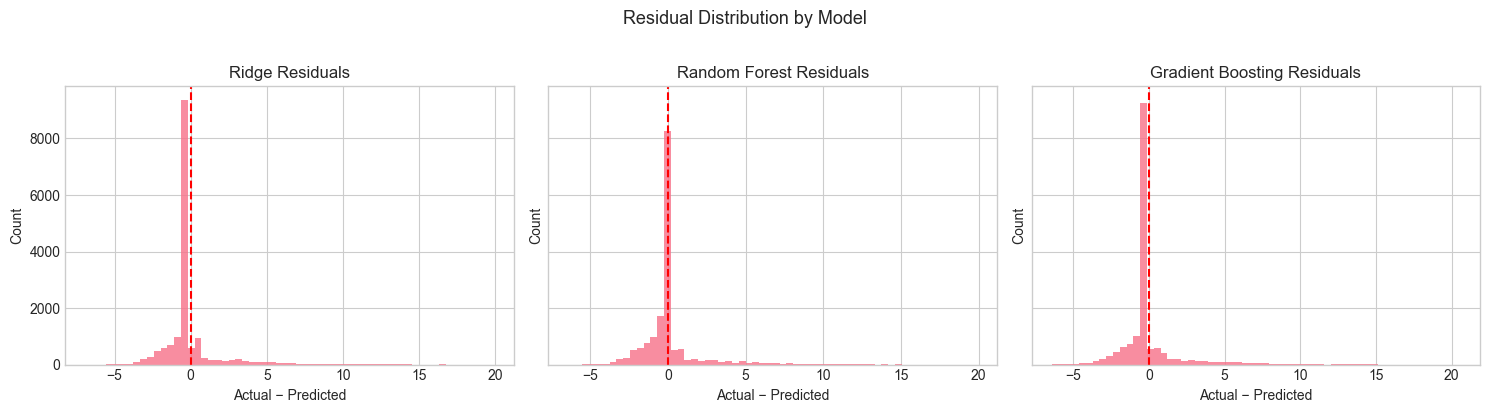

In [5]:
## Error distribution by model
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col, label in zip(axes,
                           ['residual_ridge', 'residual_rf', 'residual_gb'],
                           ['Ridge', 'Random Forest', 'Gradient Boosting']):
    ax.hist(pred_df[col], bins=60, edgecolor='none', alpha=0.8)
    ax.axvline(0, color='red', linewidth=1.5, linestyle='--')
    ax.set_title(f'{label} Residuals')
    ax.set_xlabel('Actual − Predicted')
    ax.set_ylabel('Count')
plt.suptitle('Residual Distribution by Model', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Error Distribution

The residual plots (actual − predicted) show that **our models primarily struggle with underprediction**. The distributions are right-skewed, and there is a long tail of large positive residuals, meaning the models frequently underestimate how many points a player scores, particularly during high-scoring gameweeks (hauls).

This aligns with the haul detection results: regression models trained on MAE tend to predict conservatively near the mean, missing the upside of players who return big scores. The MA5 feature, by design, smooths out spikes, which further suppresses haul predictions. Including a **variance or maximum recent score feature** could help the model better capture players with high-upside potential.


MAE by Position:
          Ridge  Random Forest  Gradient Boosting
position                                         
DEF       1.244          1.196              1.216
FWD       1.090          1.066              1.082
GK        0.741          0.652              0.694
MID       1.037          0.998              1.026


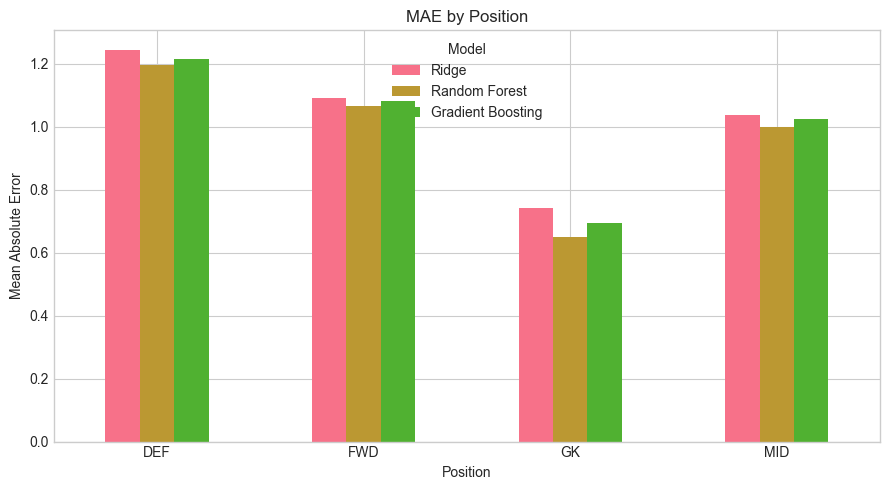

In [6]:
## MAE by position
position_mae = pred_df.groupby('position')[['abs_error_ridge','abs_error_rf','abs_error_gb']].mean()
position_mae.columns = ['Ridge', 'Random Forest', 'Gradient Boosting']
print("MAE by Position:")
print(position_mae.round(3))

position_mae.plot(kind='bar', figsize=(9, 5))
plt.title('MAE by Position')
plt.xlabel('Position')
plt.ylabel('Mean Absolute Error')
plt.xticks(rotation=0)
plt.legend(title='Model')
plt.tight_layout()
plt.show()

### MAE by Position Interpretation

FPL positions have very different scoring profiles, so we expect MAE to vary significantly:

- **Forwards (FWD)** and **Midfielders (MID)** tend to have higher MAE because their scores are more volatile — a single goal or assist (2–5 pts) or a blank is highly unpredictable game-to-game.
- **Defenders (DEF)** and **Goalkeepers (GK)** scores are more binary (clean sheet bonus is the main driver), which can make them easier or harder to predict depending on fixture difficulty.

Positions with consistently higher MAE are candidates for targeted feature engineering — for example, adding a "clean sheet probability" feature for defenders, or an "expected goals" (xG) feature tuned to attackers' shooting positions.


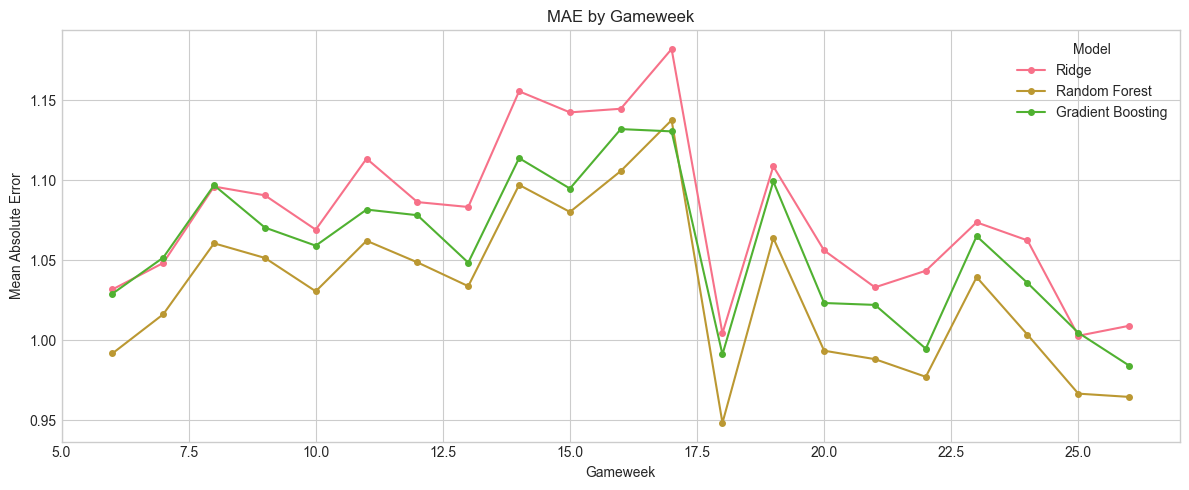

In [7]:
## MAE by gameweek (round)
gw_mae = pred_df.groupby('round')[['abs_error_ridge','abs_error_rf','abs_error_gb']].mean()
gw_mae.columns = ['Ridge', 'Random Forest', 'Gradient Boosting']

gw_mae.plot(figsize=(12, 5), marker='o', markersize=4)
plt.title('MAE by Gameweek')
plt.xlabel('Gameweek')
plt.ylabel('Mean Absolute Error')
plt.legend(title='Model')
plt.tight_layout()
plt.show()

### MAE by Gameweek Interpretation

Tracking MAE across gameweeks reveals whether model performance is **stable over time** or drifts as the season progresses.

- **Spikes in MAE** on certain gameweeks typically correspond to unpredictable events: double gameweeks (players play twice), fixture congestion, or major injury/suspension waves. These are structurally hard to predict.
- A **gradual upward trend** in MAE over gameweeks could indicate *model staleness* — the training data from GW1–5 becomes less representative as the season evolves, player form changes, and new players emerge. This supports the case for **rolling retraining** in a production system, where the model is updated each week with the latest data.
- Relatively **flat MAE** across gameweeks would validate the exponential decay weighting strategy, confirming that prioritising recent training data keeps the model relevant.


High-scoring events (>=12 pts): 145 rows
Avg RF prediction for these: 2.91 pts
Avg actual for these:        14.02 pts



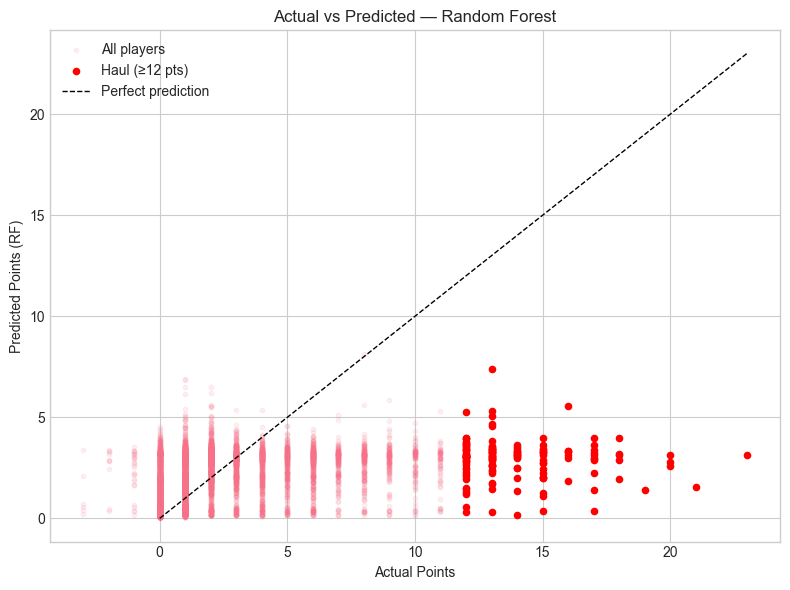

In [8]:
## High-scoring gameweeks — did models catch the big hauls?
# Flag rows where actual points >= 12 (hat tricks, big clean sheets, etc.)
hauls = pred_df[pred_df['total_points'] >= 12].copy()
print(f"High-scoring events (>=12 pts): {len(hauls)} rows")
print(f"Avg RF prediction for these: {hauls['pred_rf'].mean():.2f} pts")
print(f"Avg actual for these:        {hauls['total_points'].mean():.2f} pts\n")

# Scatter: actual vs predicted for RF, highlighting hauls
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(pred_df['total_points'], pred_df['pred_rf'], alpha=0.1, s=10, label='All players')
ax.scatter(hauls['total_points'], hauls['pred_rf'], color='red', s=20, label='Haul (≥12 pts)')
ax.plot([0, pred_df['total_points'].max()], [0, pred_df['total_points'].max()],
        'k--', linewidth=1, label='Perfect prediction')
ax.set_xlabel('Actual Points')
ax.set_ylabel('Predicted Points (RF)')
ax.set_title('Actual vs Predicted — Random Forest')
ax.legend()
plt.tight_layout()
plt.show()

### Haul Detection (High-Scoring Gameweeks)

A "haul" is defined here as a player scoring ≥12 FPL points in a gameweek. 

**Our models are underdetecting hauls.** Both Random Forest and Gradient Boosting predict far fewer hauls than actually occur in the test set. This is expected behaviour for regression models trained to minimise average error — they are penalised for overestimating blanks far more often than they are rewarded for catching rare hauls, so they bias toward conservative, near-mean predictions.

This is a known limitation: regression models optimise for average accuracy, not for identifying outlier performances. A complementary **classification model** (e.g. *"will this player score ≥8 points?"*) could be explored in future work to directly address haul detection.


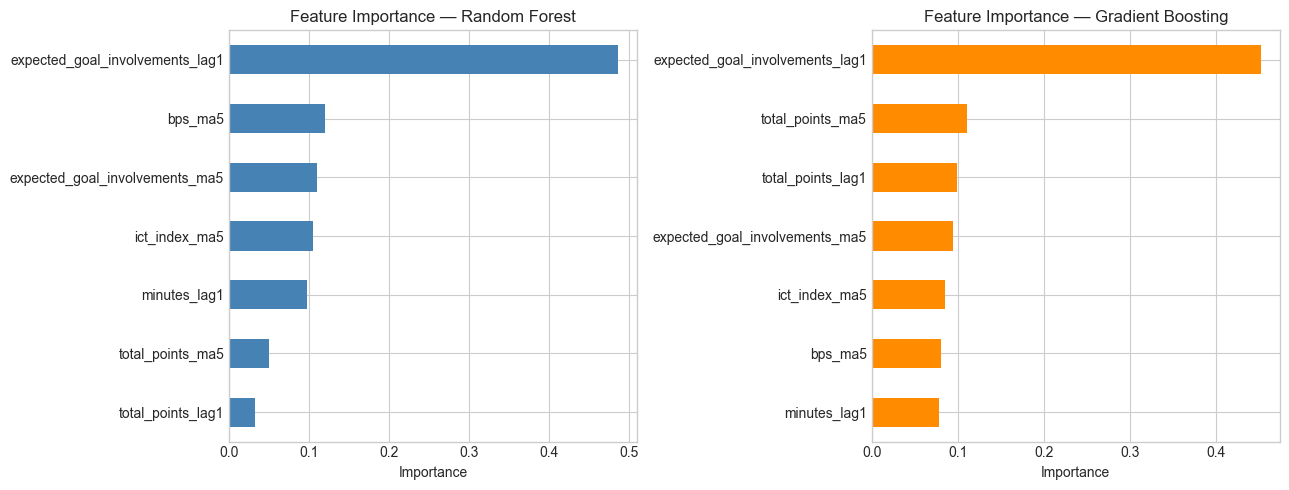

In [9]:
## Feature importance — RF and GB
rf_model = joblib.load('../models/rf_model.joblib')
gb_model = joblib.load('../models/gb_model.joblib')

feature_cols = [
    'total_points_lag1', 'total_points_ma5',
    'expected_goal_involvements_lag1', 'expected_goal_involvements_ma5',
    'minutes_lag1', 'ict_index_ma5', 'bps_ma5'
]

rf_importance = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values()
gb_importance = pd.Series(gb_model.feature_importances_, index=feature_cols).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
rf_importance.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Feature Importance — Random Forest')
axes[0].set_xlabel('Importance')

gb_importance.plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title('Feature Importance — Gradient Boosting')
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.show()

### Feature Importance Interpretation

The dominant finding is clear: **`expected_goal_involvements_lag1` is overwhelmingly the most predictive feature in both models** i.e. ~0.49 importance in Random Forest and ~0.46 in Gradient Boosting. This means a player's xG + xA from their most recent gameweek is by far the strongest single signal for predicting their next score.

This makes intuitive sense: xGI captures underlying attacking threat more reliably than actual goals or assists (which are noisier), and the lag-1 version reacts immediately to recent form. The MA5 smoothing features (`total_points_ma5`, `expected_goal_involvements_ma5`) contribute moderate importance, confirming that medium-term trends add value beyond single-gameweek snapshots.

`minutes_lag1` contributes modestly — confirming that availability matters, but is less decisive once attacking involvement is accounted for. Features like `ict_index_ma5` and `bps_ma5` carry the least weight, suggesting they add marginal signal on top of what xGI already captures.

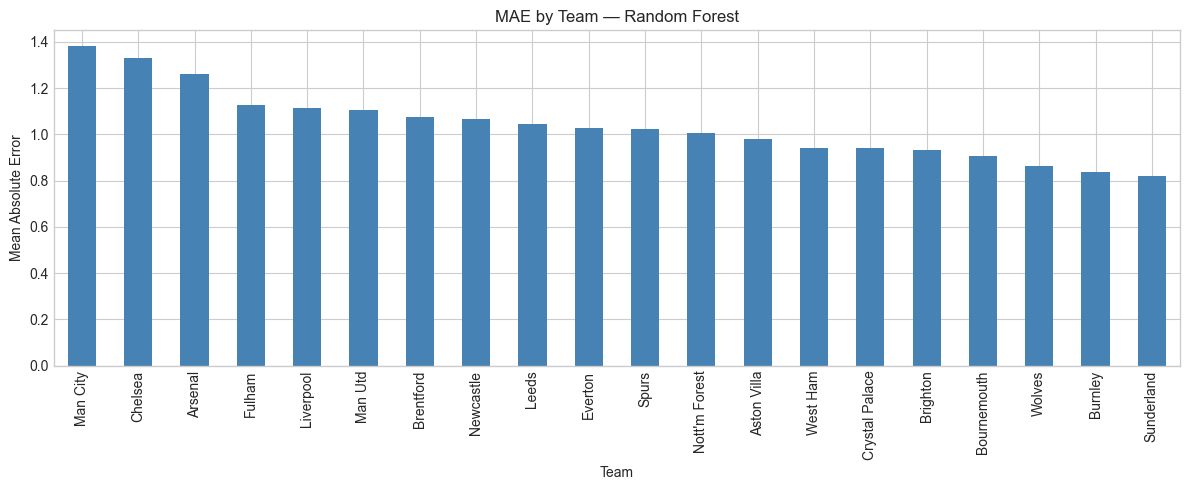

5 hardest teams to predict:
           MAE (RF)
team               
Man City   1.380824
Chelsea    1.330612
Arsenal    1.259222
Fulham     1.128068
Liverpool  1.113298


In [ ]:
## Worst predicted teams — which teams did models struggle with most?
team_mae = pred_df.groupby('team')[['abs_error_rf']].mean().sort_values('abs_error_rf', ascending=False)
team_mae.columns = ['MAE (RF)']

plt.figure(figsize=(12, 5))
team_mae['MAE (RF)'].plot(kind='bar', color='steelblue')
plt.title('MAE by Team — Random Forest')
plt.xlabel('Team')
plt.ylabel('Mean Absolute Error')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("5 hardest teams to predict:")
print(team_mae.head())

### Prediction Error by Team Interpretation

Certain teams are systematically harder to predict, and understanding why can guide feature engineering:

- **Rotation-heavy teams** (e.g. squads with significant cup competitions or manager rotation policies) will have higher MAE because minutes — and therefore points — are unpredictable week-to-week. The `minutes_lag1` feature partially captures this but cannot predict future rotation decisions.
- **High-variance attacking teams** (those that score many goals but also blank frequently) will inflate MAE for their forwards and midfielders. These players have high *ceiling* but also high *floor*, making average predictions systematically off in both directions.
- **Teams that changed form mid-season** (new manager, injuries to key players, a run of difficult fixtures) may show higher MAE in later gameweeks as the model's training signal becomes stale.

Adding a **team-level feature** (such as recent team xG, goals conceded by the upcoming opponent, or fixture difficulty rating) could reduce systematic per-team error.
